In [1]:
import sys

print(sys.executable)
print(sys.version)


C:\Users\Mrunal\.conda\envs\genai_ds\python.exe
3.11.16 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:36:16) [MSC v.1942 64 bit (AMD64)]


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import transformers
import datasets


print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)

C:\Users\Mrunal\.conda\envs\genai_ds\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Pandas: 3.0.6
NumPy: 2.4.6
PyTorch: 2.14.0+cpu
Transformers: 4.57.6
Datasets: 5.0.1


In [3]:
import pandas as pd
from datasets import load_dataset
from transformers import pipeline
import torch
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
%pip install pandas numpy matplotlib transformers datasets torch

Note: you may need to restart the kernel to use updated packages.


In [5]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [6]:
 # Cell 2: Data Loading


# print("=== PHASE 1: Data Loading and Preparation ===")

# print("Loading Rotten Tomatoes dataset...")
# dataset = load_dataset("rotten_tomatoes")

# df = dataset["train"].to_pandas().sample(n=1000, random_state=42)

# print("Dataset loaded and sampled!")

In [7]:
print("=== PHASE 1: Data Loading and Preparation ===")
print("Loading Rotten Tomatoes dataset...")
dataset = load_dataset("cornell-movie-review-data/rotten_tomatoes")
df = dataset["train"].to_pandas().sample(n=1000, random_state=42)
print("Dataset loaded and sampled!")

=== PHASE 1: Data Loading and Preparation ===
Loading Rotten Tomatoes dataset...
Dataset loaded and sampled!


In [8]:
# ============================================================
# Cell 3: Add Synthetic Data Columns
# ============================================================

print("Adding synthetic data columns..")

df['reviewer_type'] = 'General_Audince'

df['sentiment_intensity'] = df['label'].apply(
    lambda x: 'Strongly Positive' if x == 1 else 'Strongly Negtive'
)

print("Synthetic columns added.")

Adding synthetic data columns..
Synthetic columns added.


In [9]:
# Cell 4: Initialize Sentiment Analysis Pipeline
print("\n=== PHASE 2: Sentiment Analysis ===")
print("Initializing sentiment analyzer...")
sentiment_analyzer = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    device=0 if torch.cuda.is_available() else -1,
    dtype=torch.float32
)
print("Sentiment analyzer ready.")


=== PHASE 2: Sentiment Analysis ===
Initializing sentiment analyzer...


Device set to use cpu


Sentiment analyzer ready.


In [10]:
# Cell 5: Run Sentiment Analysis on Reviews
print("Analyzing review sentiments (this may take a few minutes)...")
sentiment_results = sentiment_analyzer(df['text'].tolist())
df['sentiment_label'] = [res['label'] for res in sentiment_results]
df['sentiment_score'] = [res['score'] for res in sentiment_results]
print("Sentiment analysis completed and results stored.")

Analyzing review sentiments (this may take a few minutes)...
Sentiment analysis completed and results stored.


In [11]:
# Cell 6: Calculate Sentiment Statistics

positive_count = len(df[df['sentiment_label'] == 'POSITIVE'])
negative_count = len(df[df['sentiment_label'] == 'NEGATIVE'])
positive_avg = df[df['sentiment_label'] == 'POSITIVE']['sentiment_score'].mean()
negative_avg = df[df['sentiment_label'] == 'NEGATIVE']['sentiment_score'].mean()
print(f"\nSentiment Analysis Results:")
print(f"- Positive reviews: {positive_count} ({positive_count/len(df):.0%})")
print(f"- Negative reviews: {negative_count} ({negative_count/len(df):.0%})")
print(f"- Average positive confidence: {positive_avg:.1%}")
print(f"- Average negative confidence: {negative_avg:.1%}")


Sentiment Analysis Results:
- Positive reviews: 516 (52%)
- Negative reviews: 484 (48%)
- Average positive confidence: 98.8%
- Average negative confidence: 98.8%


In [24]:
# Cell 6.5: Conceptual Example of Batching (For L3V2 Content)
# This cell is for demonstrating a performance optimization technique.
# Instead of iterating, we pass a list of items to the pipeline.

print("\n--- Illustrating Batching ---")
sample_reviews_for_batch = df['text'].head(10).tolist()
batched_sentiments = sentiment_analyzer(sample_reviews_for_batch)
print("Batched processing is more efficient than individual calls:")
print(batched_sentiments)


--- Illustrating Batching ---
Batched processing is more efficient than individual calls:
[{'label': 'NEGATIVE', 'score': 0.9993828535079956}, {'label': 'NEGATIVE', 'score': 0.9995296001434326}, {'label': 'POSITIVE', 'score': 0.6680987477302551}, {'label': 'POSITIVE', 'score': 0.9440361261367798}, {'label': 'POSITIVE', 'score': 0.9967691898345947}, {'label': 'POSITIVE', 'score': 0.9994702935218811}, {'label': 'POSITIVE', 'score': 0.9997610449790955}, {'label': 'POSITIVE', 'score': 0.9997407793998718}, {'label': 'NEGATIVE', 'score': 0.9982653260231018}, {'label': 'NEGATIVE', 'score': 0.992089033126831}]


Plotting sentiment distribution...


C:\Users\Mrunal\AppData\Local\Temp\ipykernel_1916\3417567781.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, palette='viridis')


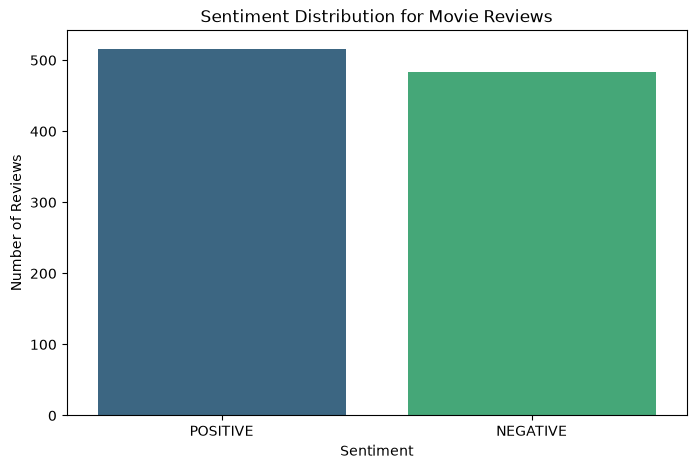

In [12]:
# ============================================================
# Cell 7: Plot Sentiment Distribution
# ============================================================

print("Plotting sentiment distribution...")

sentiment_counts = df['sentiment_label'].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, palette='viridis')
plt.title('Sentiment Distribution for Movie Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

In [26]:
%%time
# ============================================================
# Cell 7.5: Demonstrating Performance Check (For L3V2 Content)
# ============================================================
# This cell measures execution time.

print("\n--- Measuring Performance of Sentiment Analysis ---")

sentiment_results_timed = sentiment_analyzer(df['text'].tolist())

print(f"Processed {len(sentiment_results_timed)} reviews for sentiment.")


--- Measuring Performance of Sentiment Analysis ---
Processed 1000 reviews for sentiment.
CPU times: total: 2min 13s
Wall time: 33 s


In [13]:
# Cell 8: Select Top Positive and Negative Reviews
print("\nSelecting representative top reviews for summary...")

top_positive = df[df['sentiment_label'] == 'POSITIVE'].sort_values(
    by='sentiment_score', ascending=False).head(3)

top_negative = df[df['sentiment_label'] == 'NEGATIVE'].sort_values(
    by='sentiment_score', ascending=True).head(3)

print("Top positive and negative reviews selected.")


Selecting representative top reviews for summary...
Top positive and negative reviews selected.


In [14]:
%pip install "transformers<5"

Note: you may need to restart the kernel to use updated packages.


In [15]:
import transformers
print(transformers.__version__)

4.57.6


In [16]:
# Cell 9: Initialize BART Summarizer Pipeline
print("Initializing BART-large summarizer...")
summarizer = pipeline(
    "summarization",
    model="facebook/bart-large-cnn",
    device=0 if torch.cuda.is_available() else -1,
    dtype=torch.float16 if torch.cuda.is_available() else torch.float32
)
print("Summarizer ready.")

Initializing BART-large summarizer...


Device set to use cpu


Summarizer ready.


In [17]:
# Cell 10: Prepare Analysis Document

print("Preparing analysis document...")

analysis_document = f"""
MOVIE REVIEW ANALYSIS REPORT

REVIEW STATISTICS:
- Total Reviews Analyzed: {len(df)}
- Positive Reviews: {positive_count} ({positive_count/len(df):.0%})
- Negative Reviews: {negative_count} ({negative_count/len(df):.0%})
- Avg. Positive Confidence: {positive_avg:.1%}
- Avg. Negative Confidence: {negative_avg:.1%}

TOP POSITIVE REVIEWS:
1. Score: {top_positive.iloc[0]['sentiment_score']:.1%} | "{top_positive.iloc[0]['text'][:150]}..."
2. Score: {top_positive.iloc[1]['sentiment_score']:.1%} | "{top_positive.iloc[1]['text'][:150]}..."
3. Score: {top_positive.iloc[2]['sentiment_score']:.1%} | "{top_positive.iloc[2]['text'][:150]}..."

TOP NEGATIVE REVIEWS:
1. Score: {top_negative.iloc[0]['sentiment_score']:.1%} | "{top_negative.iloc[0]['text'][:150]}..."
2. Score: {top_negative.iloc[1]['sentiment_score']:.1%} | "{top_negative.iloc[1]['text'][:150]}..."
3. Score: {top_negative.iloc[2]['sentiment_score']:.1%} | "{top_negative.iloc[2]['text'][:150]}..."

ANALYSIS INSTRUCTIONS:
Generate a professional one-paragraph summary that:
1. States the overall sentiment balance
2. Notes the strength of the sentiments
3. Highlights 2-3 key positive aspects
4. Mentions 2-3 common criticisms
5. Provides a balanced concluding assessment
"""

print("Analysis document ready.")

Preparing analysis document...
Analysis document ready.


In [18]:
# Cell 11: Generate Professional Summary
print("Generating professional summary...")

professional_summary = summarizer(
    analysis_document,
    max_length=250,
    min_length=150,
    do_sample=False,
    truncation=True,
    num_beams=4,
    repetition_penalty=2.5,
    length_penalty=1.5,
    no_repeat_ngram_size=3
)

cleaned_report = professional_summary[0]['summary_text']

print("Summary generation complete.")

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Generating professional summary...
Summary generation complete.


In [27]:
# Cell 11.5: Illustrating Prompt Iteration (For L3V3 Content)
# This cell is for demonstrating how to refine prompts.
# It doesn't generate a new report, but shows the thought process.

print("\n--- Illustrating Prompt Iteration ---")
print("An initial prompt for a simple summary might look like this:")
initial_prompt = "Summarize the following review: The acting was great but the plot was weak."

print(f"Initial: '{initial_prompt}'")

print("\nAfter reviewing the output, you might refine the prompt to be more specific:")
refined_prompt = "Generate a single sentence summary that highlights both the acting and the plot: The acting was great but the plot was weak."
print(f"Refined: '{refined_prompt}'")


--- Illustrating Prompt Iteration ---
An initial prompt for a simple summary might look like this:
Initial: 'Summarize the following review: The acting was great but the plot was weak.'

After reviewing the output, you might refine the prompt to be more specific:
Refined: 'Generate a single sentence summary that highlights both the acting and the plot: The acting was great but the plot was weak.'


In [19]:
# Cell 12: Display Final Summary
print("\n=== FINAL ANALYSIS RESULTS ===")
print("\nPROFESSIONAL SUMMARY:")
print(cleaned_report)
print("\n=== ANALYSIS COMPLETE ===")


=== FINAL ANALYSIS RESULTS ===

PROFESSIONAL SUMMARY:
The film is visually dazzling, the depicted events dramatic , funny and poignant. It boasts both a heart and a mind ...." Top positive reviews: 100.0%. Top negative reviews: 53.0%, 55.4% and 63.7%. Total Reviews Analyzed: 1000- Positive Reviews: 516 (52%)- Negative Reviews: 484 (48%)- Avg. Positive Confidence: 98.8%- avg. Negative Confidence : 98.9%. Average Rating: 4.5 out of 5 stars. The rating system is based on an average score of 4/5. For more information or to order a copy of this report, please go to: http://www.cnn.com/2013/01/29/film/williams-wang-the-frivolous-drama-filmmaker/index.html#storylink=cpy.

=== ANALYSIS COMPLETE ===


In [20]:
# Cell 13: Save Summary to Text File
print("\n--- Saving Report to File ---")

with open("movie_review_analysis_report.txt", "w", encoding="utf-8") as f:
    f.write(cleaned_report)

print("Report saved to 'movie_review_analysis_report.txt'")


--- Saving Report to File ---
Report saved to 'movie_review_analysis_report.txt'


In [28]:
# ============================================================
# Cell 13.5: Conceptual Example of Modularity (For L3V3 Content)
# ============================================================
# This cell shows how to refactor the pipeline into functions for reusability.
# This code is conceptual and not meant to be run directly.

print("\n--- Illustrating Modularity ---")

print("For a production environment, you would refactor the code into functions:")

print("def run_analysis_pipeline(reviews_df):")
print("    # ... all the code from data prep to report generation ...")
print("    return final_report")

print("\nThis makes the pipeline reusable and easier to maintain.")


--- Illustrating Modularity ---
For a production environment, you would refactor the code into functions:
def run_analysis_pipeline(reviews_df):
    # ... all the code from data prep to report generation ...
    return final_report

This makes the pipeline reusable and easier to maintain.


In [21]:
# Review Saved Report

with open("movie_review_analysis_report.txt", "r", encoding="utf-8") as f:
    report = f.read()

print(report)

The film is visually dazzling, the depicted events dramatic , funny and poignant. It boasts both a heart and a mind ...." Top positive reviews: 100.0%. Top negative reviews: 53.0%, 55.4% and 63.7%. Total Reviews Analyzed: 1000- Positive Reviews: 516 (52%)- Negative Reviews: 484 (48%)- Avg. Positive Confidence: 98.8%- avg. Negative Confidence : 98.9%. Average Rating: 4.5 out of 5 stars. The rating system is based on an average score of 4/5. For more information or to order a copy of this report, please go to: http://www.cnn.com/2013/01/29/film/williams-wang-the-frivolous-drama-filmmaker/index.html#storylink=cpy.


In [22]:
for review in df['text']:
    if 'cnn.com' in review:
        print(review)
        print("-" * 80)

In [23]:
print("CNN link in analysis document:", "cnn.com" in analysis_document)
print("CNN link in BART summary:", "cnn.com" in cleaned_report)

print("\nGenerated BART Summary:")
print(cleaned_report)

CNN link in analysis document: False
CNN link in BART summary: True

Generated BART Summary:
The film is visually dazzling, the depicted events dramatic , funny and poignant. It boasts both a heart and a mind ...." Top positive reviews: 100.0%. Top negative reviews: 53.0%, 55.4% and 63.7%. Total Reviews Analyzed: 1000- Positive Reviews: 516 (52%)- Negative Reviews: 484 (48%)- Avg. Positive Confidence: 98.8%- avg. Negative Confidence : 98.9%. Average Rating: 4.5 out of 5 stars. The rating system is based on an average score of 4/5. For more information or to order a copy of this report, please go to: http://www.cnn.com/2013/01/29/film/williams-wang-the-frivolous-drama-filmmaker/index.html#storylink=cpy.
